# Storm intensity levels: analysis (#71)

Distributions of per-storm measures over one month of GLM data, to support the choice of public
intensity levels ([ADR 0009](../adr/0009-storm-intensity-levels.md)).

**Data.** GLM East and West, 2026-09-08 to 2026-10-08 (29 days: 2026-09-22 is missing upstream),
64 M flashes in `silver.flashes`. `gold/storm_cells`, `gold/storm_tracks` and `gold/storms` were
computed with the branch's functions and default parameters by
[`storm_metrics.py`](storm-intensity/storm_metrics.py), once with the fixed hot spot filter and once
without, into a separate catalog. Per-storm measures that `gold/storms` lacks (energy, peak rate,
counts per satellite) come from the flashes of each storm's cells.

**Measures per storm.**

| Column | Meaning |
|---|---|
| `flashes` | Flashes of the satellite that saw the storm best (see *East and West*) |
| `energy_fj` | Total optical energy of those flashes, femtojoules (GLM `energy_raw`) |
| `peak_rate` | Highest number of flashes in one minute, same satellite |
| `max_area_km2` | Largest convex hull of a cell of the storm |
| `duration_min` | First to last flash |

**Re-run.** From `data/`, with `SCINTILLE_LAKE_*` pointing at a lake holding the month:
`STORM_ANALYSIS_DIR=<dir> uv run python ../docs/analysis/storm-intensity/storm_metrics.py <step>`
for `export`, `cells`, `tracks`, `metrics` in turn (about 25 min), then execute this notebook with
`STORM_METRICS_DIR=<dir>/out` in an environment with Polars and Matplotlib.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
DATA = Path(os.environ.get("STORM_METRICS_DIR", "storm-intensity/data"))
FIG = Path("storm-intensity")

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
EAST, WEST, BOTH = "#2a78d6", "#eb6834", "#1baf7a"
LEVELS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 9, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 9.5, "axes.titleweight": "bold",
})


def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    print(name, round((FIG / name).stat().st_size / 1024), "KB")

## Population

Storms still open at the end of the month are left out. So are storms starting in the first 24 h
after each data start (2026-09-08 and 2026-09-23): the hot spot rule needs 24 h of lookback, and
without it a fixed hot spot passes as a storm for about 12 h. In production the lookback is always
there.

In [2]:
WARMUP = [("2026-09-08", "2026-09-09"), ("2026-09-23", "2026-09-24")]


def load(mode):
    df = pl.read_parquet(DATA / mode / "storm_metrics.parquet").filter("closed")
    warm = pl.lit(False)
    for a, b in WARMUP:
        start = pl.col("storm_start").dt.date().cast(pl.String)
        warm |= (start >= a) & (start < b)
    return df.with_columns(warmup=warm)


raw = load("filtered")
storms = raw.filter(~pl.col("warmup")).select(
    "storm_id", "storm_start", "lat", "lon", "satellite", "steps", "flash_count",
    pl.col("flash_count_one_source").alias("flashes"),
    (pl.col("energy_one_source_j") * 1e15).alias("energy_fj"),
    pl.col("peak_rate_one_source").cast(pl.Int64).alias("peak_rate"),
    "max_area_km2", "duration_min",
    (pl.col("energy_j") / pl.col("energy_exact_j")).alias("bounds_ratio"),
)
MEASURES = ["flashes", "energy_fj", "peak_rate", "max_area_km2", "duration_min"]
print(f"closed storms {raw.height:,}, after warm-up exclusion {storms.height:,}")
storms.select(MEASURES).describe(percentiles=[0.5, 0.8, 0.95, 0.99, 0.999])

closed storms 170,960, after warm-up exclusion 159,412


statistic,flashes,energy_fj,peak_rate,max_area_km2,duration_min
str,f64,f64,f64,f64,f64
"""count""",159412.0,159412.0,159412.0,159412.0,159412.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",274.140052,50366.543503,5.635611,627.140674,60.559368
"""std""",5831.024612,682361.09952,12.738597,2766.541681,82.392739
"""min""",1.0,2.285142,1.0,0.000226,0.016667
"""50%""",24.0,5087.11223,3.0,151.243437,31.033333
"""80%""",106.0,25947.446435,6.0,569.648615,85.5
"""95%""",742.0,155966.054228,19.0,2364.774253,208.183333
"""99%""",4293.0,785361.332893,50.0,7939.406206,401.4


## Distributions

Every measure is heavy tailed: the median storm is a short burst of a few dozen flashes, while the
top 1 % hold thousands. Percentile thresholds on log-like scales are the natural fit.

distributions.png 37 KB


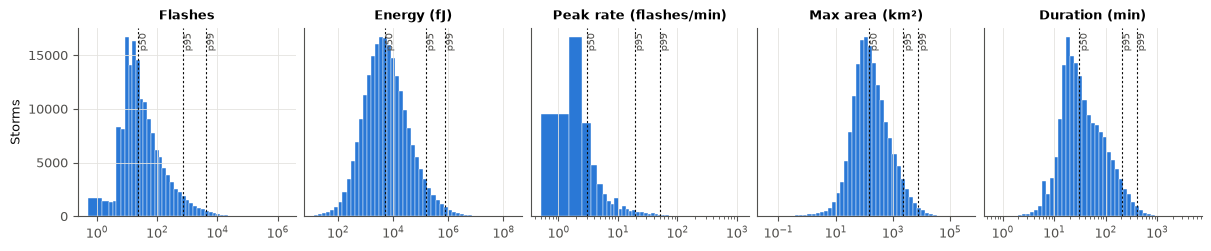

In [3]:
labels = {
    "flashes": "Flashes", "energy_fj": "Energy (fJ)", "peak_rate": "Peak rate (flashes/min)",
    "max_area_km2": "Max area (km²)", "duration_min": "Duration (min)",
}
fig, axes = plt.subplots(1, 5, figsize=(12, 2.4), constrained_layout=True)
for ax, m in zip(axes, MEASURES):
    v = storms[m].to_numpy().astype(float)
    v = v[v > 0]
    lo = max(v.min(), np.quantile(v, 0.001))
    bins = np.logspace(np.log10(lo), np.log10(v.max()), 50)
    if m in ("flashes", "peak_rate"):
        bins = np.unique(np.round(bins)) + 0.5
        bins = np.concatenate([[bins[0] - 1], bins])
    ax.hist(v, bins=bins, color=EAST, edgecolor="white", linewidth=0.3)
    ax.set_xscale("log")
    for q in (0.5, 0.95, 0.99):
        x = np.quantile(v, q)
        ax.axvline(x, color=INK, lw=0.8, ls=(0, (2, 2)))
        ax.text(x, ax.get_ylim()[1] * 0.97, f"p{int(q * 100)}", fontsize=7, color=MUTED,
                ha="left", va="top", rotation=90)
    ax.set_title(labels[m])
    ax.set_yticks([]) if m != "flashes" else ax.set_ylabel("Storms")
save(fig, "distributions.png")

### Energy from track bounds

The ticket asks for energy taken from silver within the bounds of each track step (bbox and time
range of the cell, inside its own hour). That is what a production asset can do without storing
flash membership. Compared with the exact sum over each storm's own flashes:

In [4]:
exact = raw.filter(~pl.col("warmup"))
exact.select(
    pl.corr(pl.col("energy_j"), pl.col("energy_exact_j"), method="spearman").alias("spearman"),
    (pl.col("energy_j").sum() / pl.col("energy_exact_j").sum()).alias("total_ratio"),
    (pl.col("energy_j") / pl.col("energy_exact_j")).median().alias("median_ratio"),
    (pl.col("energy_j") / pl.col("energy_exact_j")).quantile(0.99).alias("p99_ratio"),
)

spearman,total_ratio,median_ratio,p99_ratio
f64,f64,f64,f64
0.998274,1.065181,1.0,1.397493


The bbox picks up a few unclustered flashes and some flashes of neighbouring cells, so it reads
about 6 % high in total; the ranking is the same (Spearman ≈ 1). Either way works for a level.

## Correlations

Spearman rank correlations between the measures.

correlations.png 31 KB


,Flashes,Energy,Peak rate,Max area,Duration
str,f64,f64,f64,f64,f64
"""Flashes""",1.0,0.77,0.85,0.74,0.8
"""Energy""",0.77,1.0,0.61,0.76,0.73
"""Peak rate""",0.85,0.61,1.0,0.61,0.55
"""Max area""",0.74,0.76,0.61,1.0,0.79
"""Duration""",0.8,0.73,0.55,0.79,1.0


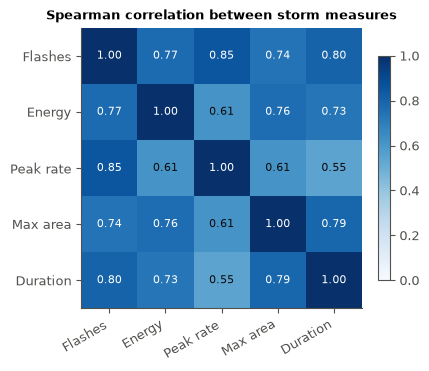

In [5]:
ranks = storms.select(pl.col(m).rank() for m in MEASURES).to_numpy()
corr = np.corrcoef(ranks, rowvar=False)
short = ["Flashes", "Energy", "Peak rate", "Max area", "Duration"]
fig, ax = plt.subplots(figsize=(4.2, 3.6), constrained_layout=True)
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(5), short, rotation=30, ha="right")
ax.set_yticks(range(5), short)
ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if corr[i, j] > 0.7 else INK)
ax.set_title("Spearman correlation between storm measures")
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "correlations.png")
pl.DataFrame(corr.round(2), schema=short).insert_column(0, pl.Series("", short))

The flash count is the hub: it correlates with every other measure (0.74 to 0.86). Peak rate
and duration are the least related pair (0.55): a long, slow storm and a short, violent burst are
different things, which a score with both flash count and peak rate can tell apart.

## East and West

Storms are split by the satellites that saw them. Where the two GLM fields of view overlap (about
105° W to 75° W) most flashes are detected twice, once per satellite, and `silver.flashes` keeps
both (`overlap` quality flag), so `gold/storms.flash_count` nearly doubles there. Counting the
flashes of the satellite that saw the storm best removes that bias; all measures here do so.

In [6]:
raw.filter(~pl.col("warmup")).group_by("satellite").agg(
    pl.len().alias("storms"),
    pl.col("flash_count").median().alias("flash_count_both_median"),
    pl.col("flash_count_one_source").median().alias("flashes_median"),
    (pl.col("flash_count") / pl.col("flash_count_one_source")).median().alias("double_count_ratio"),
).sort("satellite")

satellite,storms,flash_count_both_median,flashes_median,double_count_ratio
str,u32,f64,f64,f64
"""both""",64466,32.0,18.0,1.882353
"""glm-east""",86557,31.0,31.0,1.0
"""glm-west""",8389,18.0,18.0,1.0


east-west.png 64 KB


satellite,flashes,peak_rate,max_area_km2,duration_min,energy_per_flash
str,f64,f64,f64,f64,f64
"""both""",18.0,2.0,168.783025,29.55,225.950904
"""glm-east""",31.0,3.0,148.026608,34.05,134.587639
"""glm-west""",18.0,3.0,90.578661,17.616667,190.034385


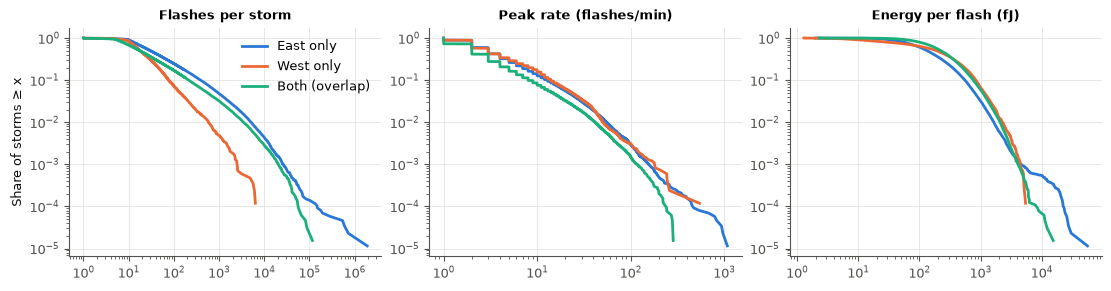

In [7]:
groups = [("glm-east", "East only", EAST), ("glm-west", "West only", WEST), ("both", "Both (overlap)", BOTH)]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), constrained_layout=True)
per_flash = storms.with_columns(energy_per_flash=pl.col("energy_fj") / pl.col("flashes"))
for ax, (m, title) in zip(axes, [("flashes", "Flashes per storm"), ("peak_rate", "Peak rate (flashes/min)"),
                                 ("energy_per_flash", "Energy per flash (fJ)")]):
    for key, name, color in groups:
        v = np.sort(per_flash.filter(pl.col("satellite") == key)[m].to_numpy().astype(float))
        ax.plot(v, 1 - np.arange(v.size) / v.size, color=color, lw=2, label=name)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(title)
axes[0].set_ylabel("Share of storms ≥ x")
axes[0].legend(frameon=False)
save(fig, "east-west.png")
per_flash.group_by("satellite").agg(
    pl.col("flashes", "peak_rate", "max_area_km2", "duration_min", "energy_per_flash").median()
).sort("satellite")

- Without de-duplication, overlap storms would look 1.9 times bigger than they are (median ratio
  above), so a level based on `gold/storms.flash_count` would favour the Americas' overlap zone.
- After de-duplication, overlap and West-only storms are a bit smaller than East-only ones
  (median 18 against 31 flashes): West-only storms (5 % of the total) are mostly over the open
  eastern Pacific, and the overlap zone sits at the edge of both fields of view, where detection
  efficiency is lower. The top levels are dominated by East (South America), as the map shows.
- Energy per flash differs between groups by up to 1.7 times (median). GLM East and West are
  calibrated separately, and `intensity` stays null until cross-source calibration (#33). Energy would make the level
  depend on which satellite saw the storm, and it will not compare with MTG LI either.

## Effect of the fixed hot spot filter

Same month, same parameters, with and without the hot spot rule of #179. All closed storms here,
warm-up days included, since that is where the two big spots start.

In [8]:
noflt = load("unfiltered")
flt = raw
hot = lambda d: d.filter((pl.col("duration_min") > 600) & (pl.col("max_area_km2") < 300))
summary = pl.DataFrame({
    "run": ["without filter", "with filter"],
    "storms": [noflt.height, flt.height],
    "flashes_in_storms": [noflt["flash_count"].sum(), flt["flash_count"].sum()],
    "p99_flash_count": [noflt["flash_count"].quantile(0.99), flt["flash_count"].quantile(0.99)],
    "max_flash_count": [noflt["flash_count"].max(), flt["flash_count"].max()],
    "hotspot_like_storms": [hot(noflt).height, hot(flt).height],
})
print("hotspot-like: duration > 10 h and largest cell < 300 km²")
summary

hotspot-like: duration > 10 h and largest cell < 300 km²


run,storms,flashes_in_storms,p99_flash_count,max_flash_count,hotspot_like_storms
str,i64,i64,f64,i64,i64
"""without filter""",170979,60244951,5425.0,1898713,27
"""with filter""",170960,58148538,5405.0,1898708,15


hotspots.png 32 KB
without filter
shape: (6, 7)
┌──────────────────┬─────────────────────────┬─────────────┬──────────────┬──────────────┬────────────┬─────────────┐
│ storm_id         ┆ storm_start             ┆ flash_count ┆ duration_min ┆ max_area_km2 ┆ lat        ┆ lon         │
│ ---              ┆ ---                     ┆ ---         ┆ ---          ┆ ---          ┆ ---        ┆ ---         │
│ str              ┆ datetime[μs, UTC]       ┆ i64         ┆ f64          ┆ f64          ┆ f64        ┆ f64         │
╞══════════════════╪═════════════════════════╪═════════════╪══════════════╪══════════════╪════════════╪═════════════╡
│ cf2333ed1e295778 ┆ 2026-09-08 00:00:00 UTC ┆ 953478      ┆ 20159.966667 ┆ 38.785183    ┆ -21.315457 ┆ -121.774154 │
│ a80bfd0964ade3bb ┆ 2026-09-23 00:00:00 UTC ┆ 865403      ┆ 16094.5      ┆ 36.729642    ┆ 21.316316  ┆ -28.655738  │
│ c292fbdd8b2ac95f ┆ 2026-10-05 04:00:00 UTC ┆ 95297       ┆ 1407.95      ┆ 17.10637     ┆ 21.314107  ┆ -28.65978   │
│ f24038

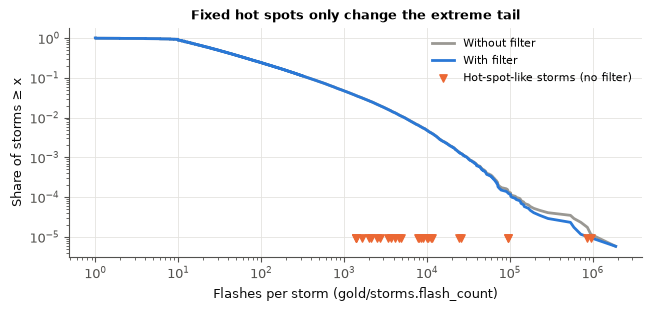

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.0), constrained_layout=True)
for d, name, color in [(noflt, "Without filter", "#9a9893"), (flt, "With filter", EAST)]:
    v = np.sort(d["flash_count"].to_numpy().astype(float))
    ax.plot(v, 1 - np.arange(v.size) / v.size, color=color, lw=2, label=name)
h = hot(noflt)
ax.scatter(h["flash_count"], [1 / noflt.height * 1.6] * h.height, marker="v", s=28,
           color=WEST, label="Hot-spot-like storms (no filter)", zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Flashes per storm (gold/storms.flash_count)")
ax.set_ylabel("Share of storms ≥ x")
ax.set_title("Fixed hot spots only change the extreme tail")
ax.legend(frameon=False, fontsize=8)
save(fig, "hotspots.png")
cols = ["storm_id", "storm_start", "flash_count", "duration_min", "max_area_km2", "lat", "lon"]
print("without filter")
print(hot(noflt).sort("flash_count", descending=True).select(cols).head(6))
print("with filter")
print(hot(flt).sort("flash_count", descending=True).select(*cols, "warmup").head(6))

- Without the filter, two hot spots (21.3° N 28.7° W and 21.3° S 121.8° W) become "storms" of
  11 to 14 days with close to a million flashes each on a few km²: the second and third largest
  storms of the month by flash count, ahead of real mesoscale systems.
- With the filter they only survive during the warm-up (12 to 14 h after each data start, left
  out of the population above). Note: the refined hot-spot rule (#180) removes most of these
  pixels; the bursty one near 3.5°S 22.3°W remains partly unfiltered, so levels 4–5 may still
  contain a few artefacts.
- The bulk of the distribution does not move: storm count and p99 change by well under 1 %. The
  filter matters for the top level only, which is exactly where a false storm would be most
  visible.

## Proposed score and levels

**Score.** `score = sqrt(flashes × peak_rate)`: the geometric mean of the total flash count and the
peak one-minute rate, both counted on the satellite that saw the storm best.

- Simple to state publicly: *the level grows with how much lightning a storm produced and how
  fast it flashed at its peak.*
- Both terms only grow during a storm's life, so a live storm's level can rise but never drop
  (#72 recomputes it while the storm is active).
- It uses the two measures that are both informative and robust: area depends on the clustering
  parameters and on the hull of few flashes, duration rewards slow storms, energy is not
  comparable across satellites (above).

**Thresholds** at the 50th, 80th, 95th and 99th percentiles of the month, rounded.

In [10]:
storms = storms.with_columns(score=(pl.col("flashes") * pl.col("peak_rate")).sqrt())
print("score percentiles:", {q: round(storms["score"].quantile(q), 1) for q in (0.5, 0.8, 0.95, 0.99)})
print("flashes percentiles:", {q: storms["flashes"].quantile(q) for q in (0.5, 0.6, 0.8, 0.9, 0.95, 0.99)})


def level(col, cuts):
    expr = pl.lit(1)
    for k, c in enumerate(cuts):
        expr = pl.when(pl.col(col) >= c).then(pl.lit(k + 2)).otherwise(expr)
    return expr


SCHEMES = {
    "proposal: score, 5 levels": ("score", [8, 25, 120, 450]),
    "variant A: score, 4 levels": ("score", [10, 50, 450]),
    "variant B: flashes only, 5 levels": ("flashes", [25, 100, 750, 4000]),
}
NAMES = {
    5: ["Light", "Moderate", "Strong", "Intense", "Exceptional"],
    4: ["Light", "Moderate", "Strong", "Exceptional"],
}
for i, (name, (col, cuts)) in enumerate(SCHEMES.items()):
    storms = storms.with_columns(level(col, cuts).alias(f"level_{i}"))
counts = []
for i, (name, (col, cuts)) in enumerate(SCHEMES.items()):
    n = len(cuts) + 1
    c = storms.group_by(f"level_{i}").len().sort(f"level_{i}")
    for lv, k in c.iter_rows():
        counts.append((name, lv, NAMES[n][lv - 1], col, None if lv == 1 else cuts[lv - 2], k,
                       round(100 * k / storms.height, 1), round(k / 29, 1)))
counts = pl.DataFrame(counts, schema=["scheme", "level", "name", "measure", "from", "storms",
                                      "share_%", "per_day"], orient="row")
counts

score percentiles: {0.5: 7.9, 0.8: 24.7, 0.95: 114.2, 0.99: 444.5}
flashes percentiles: {0.5: 24.0, 0.6: 35.0, 0.8: 106.0, 0.9: 292.0, 0.95: 742.0, 0.99: 4293.0}


scheme,level,name,measure,from,storms,share_%,per_day
str,i64,str,str,i64,i64,f64,f64
"""proposal: score, 5 levels""",1,"""Light""","""score""",null,80406,50.4,2772.6
"""proposal: score, 5 levels""",2,"""Moderate""","""score""",8,47403,29.7,1634.6
"""proposal: score, 5 levels""",3,"""Strong""","""score""",25,24038,15.1,828.9
"""proposal: score, 5 levels""",4,"""Intense""","""score""",120,6004,3.8,207.0
"""proposal: score, 5 levels""",5,"""Exceptional""","""score""",450,1561,1.0,53.8
"""variant A: score, 4 levels""",1,"""Light""","""score""",null,93095,58.4,3210.2
"""variant A: score, 4 levels""",2,"""Moderate""","""score""",10,49081,30.8,1692.4
"""variant A: score, 4 levels""",3,"""Strong""","""score""",50,15675,9.8,540.5
"""variant A: score, 4 levels""",4,"""Exceptional""","""score""",450,1561,1.0,53.8


In [11]:
prop = storms.group_by("level_0").agg(
    pl.len().alias("storms"),
    pl.col("flashes").median().alias("flashes"),
    pl.col("peak_rate").median().alias("peak_rate"),
    pl.col("max_area_km2").median().round(0).alias("max_area_km2"),
    pl.col("duration_min").median().round(0).alias("duration_min"),
    (pl.col("satellite") == "glm-west").mean().round(3).alias("west_only_share"),
).sort("level_0")
prop

level_0,storms,flashes,peak_rate,max_area_km2,duration_min,west_only_share
i32,u32,f64,f64,f64,f64,f64
1,80406,12.0,2.0,76.0,20.0,0.055
2,47403,44.0,4.0,234.0,46.0,0.061
3,24038,218.0,9.0,821.0,108.0,0.04
4,6004,1449.0,27.0,3045.0,224.0,0.015
5,1561,7716.0,67.0,10934.0,410.0,0.008


Typical storm per proposed level (medians above) and the public description drafted from them:

| Level | Name | Description (public) |
|---|---|---|
| 1 | Light | A brief, isolated burst: a dozen flashes in about twenty minutes. |
| 2 | Moderate | An ordinary thunderstorm, a few flashes a minute for under an hour. |
| 3 | Strong | A well-developed storm: hundreds of flashes over about two hours. |
| 4 | Intense | A large, very active storm, a flash every two seconds at its peak, for hours. |
| 5 | Exceptional | Among the most electric storms on Earth: thousands of flashes, more than one per second at its peak. |

levels.png 36 KB


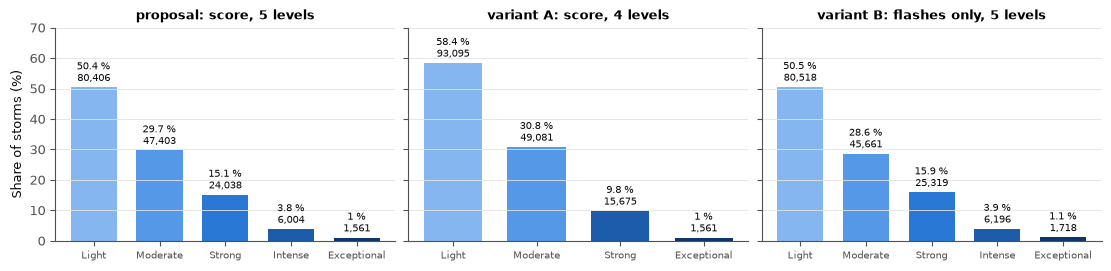

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), constrained_layout=True, sharey=True)
for ax, (i, (name, (col, cuts))) in zip(axes, enumerate(SCHEMES.items())):
    c = counts.filter(pl.col("scheme") == name)
    colors = LEVELS if len(cuts) == 4 else [LEVELS[0], LEVELS[1], LEVELS[3], LEVELS[4]]
    bars = ax.bar(c["name"], c["share_%"], color=colors, width=0.7)
    for b, s, k in zip(bars, c["share_%"], c["storms"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{s:g} %\n{k:,}",
                ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_title(name)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of storms (%)")
axes[0].set_ylim(0, 70)
save(fig, "levels.png")

### Where the levels fall

Storm centroids for the month, levels 3 to 5 of the proposal.

map.png 102 KB


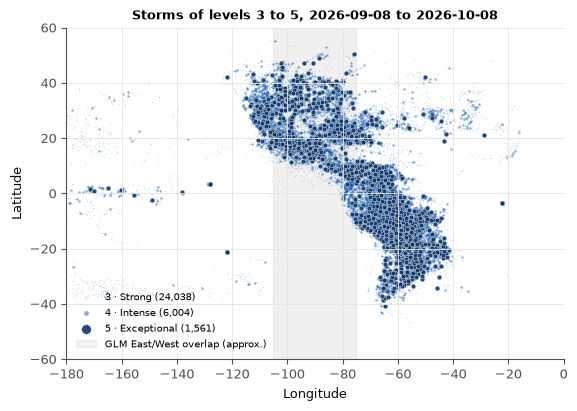

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.0), constrained_layout=True)
for lv, size, alpha in [(3, 0.6, 0.25), (4, 3, 0.5), (5, 12, 0.9)]:
    s = storms.filter(pl.col("level_0") == lv)
    ax.scatter(s["lon"], s["lat"], s=size, color=LEVELS[lv - 1],
               alpha=alpha, linewidths=0.3 if lv == 5 else 0, edgecolors="white",
               label=f"{lv} · {NAMES[5][lv - 1]} ({s.height:,})")
ax.axvspan(-105, -75, color=GRID, alpha=0.5, zorder=0, label="GLM East/West overlap (approx.)")
ax.set_xlim(-180, 0)
ax.set_ylim(-60, 60)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Storms of levels 3 to 5, 2026-09-08 to 2026-10-08")
ax.legend(frameon=False, fontsize=7.5, loc="lower left", markerscale=2)
save(fig, "map.png")

### Agreement between the proposal and variant B

Share of storms per (proposal level, flash-count level). Most storms land on the diagonal; the
off-diagonal ones are long, slow storms (higher by count) or short bursts (higher by score).

In [14]:
ct = storms.group_by("level_0", "level_2").len().pivot(
    on="level_2", index="level_0", values="len", sort_columns=True).sort("level_0").fill_null(0)
diag = storms.filter(pl.col("level_0") == pl.col("level_2")).height / storms.height
print(f"same level: {diag:.1%}")
ct

same level: 89.7%


level_0,1,2,3,4,5
i32,u32,u32,u32,u32,u32
1,75499,4907,0,0,0
2,5019,39080,3304,0,0
3,0,1674,21554,810,0
4,0,0,461,5317,226
5,0,0,0,69,1492


## Limits

- **29 days, one season.** September to early October: northern late summer, start of the
  southern spring storms over South America. Percentiles will shift with the season (more large
  storms in the austral summer, fewer over North America in winter). Freeze the thresholds as
  absolute values and re-check them after a full year rather than recomputing them live.
- **GLM only.** No MTG Lightning Imager yet: Europe, Africa and the Indian Ocean are absent, and LI
  has a different detection efficiency and energy scale. The score uses counts and rates, which
  transfer better than energy, but LI storms should be checked against these thresholds once
  they flow.
- **Detection efficiency** varies across a GLM field of view (lower at the edges), and the overlap
  de-duplication here keeps the better satellite per storm, which is a proxy, not a flash match.
- **Parameters.** Storm boundaries depend on ST-DBSCAN and tracking parameters; changing them
  changes the counts and calls for a re-run of this notebook.
- **Cut storms.** Storms crossing the data gap of 2026-09-22 are cut in two.